# Обучение модели Airbnb
Цель — предсказать цену за ночь по характеристикам объявления. Случайное разбиение оценивает качество на новых объявлениях из того же снимка.

In [2]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

RANDOM_STATE = 42

In [4]:
load_dotenv()

S3_BUCKET = "mlops26-course-bucket"
S3_KEY = "prepared/listings.csv"

s3 = boto3.client(
    "s3",
    endpoint_url="https://storage.yandexcloud.net",
    region_name="ru-central1"
)

response = s3.get_object(
    Bucket=S3_BUCKET,
    Key=S3_KEY
)

with response["Body"] as body:
    df = pd.read_csv(
        body,
        dtype={"listing_id": str}
    )

print("Размер датасета:", df.shape)
display(df.head())

/Users/polina.sokol/Projects/airbnb-mlops/.venv/lib/python3.9/site-packages/boto3/compat.py:89: PythonDeprecationWarning: Boto3 will no longer support Python 3.9 starting April 29, 2026. To continue receiving service updates, bug fixes, and security updates please upgrade to Python 3.10 or later. More information can be found here: https://aws.amazon.com/blogs/developer/python-support-policy-updates-for-aws-sdks-and-tools/
  warnings.warn(warning, PythonDeprecationWarning)


Размер датасета: (20151, 13)


,listing_id,snapshot_date,latitude,longitude,accommodates,bathrooms,bedrooms,beds,minimum_nights,neighbourhood_cleansed,property_type,room_type,price
0,2145993,2026-09-17,51.511100,-0.198250,2,1.0,1.0,1.0,4.0,Kensington and Chelsea,Entire rental unit,Entire home/apt,251.75
1,846381013872498937,2026-09-17,51.599540,-0.064500,6,1.5,3.0,4.0,2.0,Haringey,Entire home,Entire home/apt,201.60
2,1230990949123993577,2026-06-19,51.371535,-0.097551,2,1.0,NaN,1.0,1.0,Croydon,Private room in rental unit,Private room,73.00
3,54178450,2026-09-17,51.390740,-0.273480,2,1.0,1.0,1.0,1.0,Kingston upon Thames,Entire condo,Entire home/apt,126.00
4,1297347987655075325,2026-03-21,51.517398,0.012953,4,1.0,1.0,2.0,3.0,Newham,Entire rental unit,Entire home/apt,147.00


In [5]:
df.info()

print("\nПропуски:")
print(df.isna().sum())

print("\nДубликаты:", df.duplicated().sum())

print("\nУникальные объявления:",
      df["listing_id"].nunique())

display(df["price"].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20151 entries, 0 to 20150
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   listing_id              20151 non-null  object 
 1   snapshot_date           20151 non-null  object 
 2   latitude                20151 non-null  float64
 3   longitude               20151 non-null  float64
 4   accommodates            20151 non-null  int64  
 5   bathrooms               20120 non-null  float64
 6   bedrooms                18603 non-null  float64
 7   beds                    19469 non-null  float64
 8   minimum_nights          20111 non-null  float64
 9   neighbourhood_cleansed  20151 non-null  object 
 10  property_type           20151 non-null  object 
 11  room_type               20151 non-null  object 
 12  price                   20151 non-null  float64
dtypes: float64(7), int64(1), object(5)
memory usage: 2.0+ MB

Пропуски:
listing_id             

count    20151.000000
mean       250.966359
std        484.703977
min          4.320000
25%         99.550000
50%        174.000000
75%        286.000000
max      23686.000000
Name: price, dtype: float64

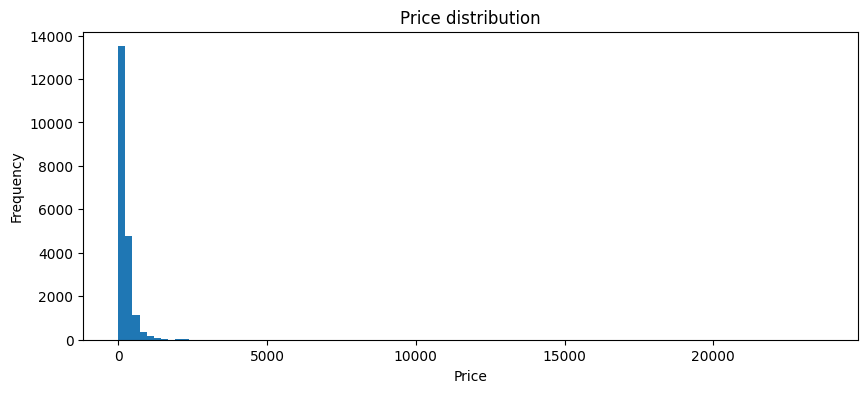

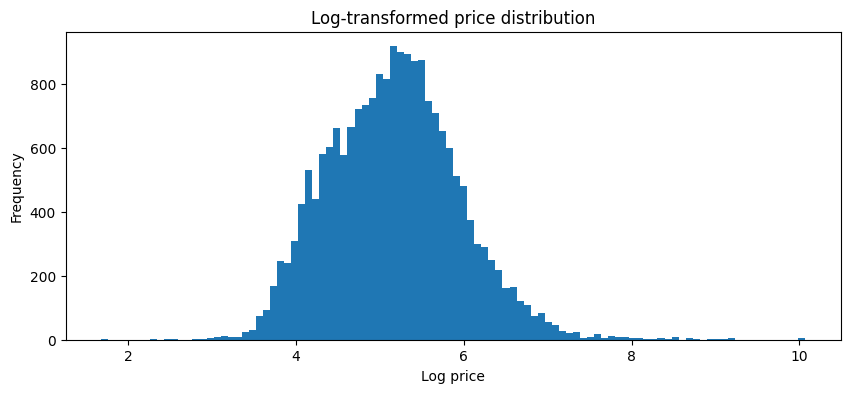

In [6]:
plt.figure(figsize=(10, 4))
plt.hist(df["price"], bins=100)
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.title("Price distribution")
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(np.log1p(df["price"]), bins=100)
plt.xlabel("Log price")
plt.ylabel("Frequency")
plt.title("Log-transformed price distribution")
plt.show()

In [7]:
df = df.drop_duplicates().copy()

df = df[
    df["price"].notna()
    & np.isfinite(df["price"])
    & (df["price"] > 0)
].reset_index(drop=True)

print("Размер после очистки:", df.shape)

Размер после очистки: (19191, 13)


In [8]:
NUM_FEATURES = [
    "latitude",
    "longitude",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "beds",
    "minimum_nights"
]

CAT_FEATURES = [
    "neighbourhood_cleansed",
    "property_type",
    "room_type"
]

FEATURES = NUM_FEATURES + CAT_FEATURES
TARGET = "price"

X = df[FEATURES].copy()
y = df[TARGET].copy()

groups = df["listing_id"]

In [9]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

train_ids = set(groups.iloc[train_idx])
test_ids = set(groups.iloc[test_idx])

assert train_ids.isdisjoint(test_ids)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

print("Уникальных ID в train:", len(train_ids))
print("Уникальных ID в test:", len(test_ids))
print("Пересечение ID:", len(train_ids & test_ids))

Train: (15352, 10)
Test: (3839, 10)
Уникальных ID в train: 7188
Уникальных ID в test: 1798
Пересечение ID: 0


In [10]:
num_imputer = SimpleImputer(strategy="median")

X_train_num = num_imputer.fit_transform(
    X_train[NUM_FEATURES]
)

X_test_num = num_imputer.transform(
    X_test[NUM_FEATURES]
)

In [11]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat = encoder.fit_transform(
    X_train[CAT_FEATURES]
)

X_test_cat = encoder.transform(
    X_test[CAT_FEATURES]
)

In [12]:
X_train_processed = np.hstack([
    X_train_num,
    X_train_cat
])

X_test_processed = np.hstack([
    X_test_num,
    X_test_cat
])

print("Train:", X_train_processed.shape)
print("Test:", X_test_processed.shape)

Train: (15352, 98)
Test: (3839, 98)


In [13]:
baseline = DummyRegressor(
    strategy="median"
)

baseline.fit(X_train_processed, y_train)

baseline_pred = baseline.predict(
    X_test_processed
)

In [14]:
model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

model.fit(
    X_train_processed,
    np.log1p(y_train)
)

y_pred = np.expm1(
    model.predict(X_test_processed)
)

In [15]:
def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(
            mean_squared_error(y_true, y_pred)
        ),
        "R2": r2_score(y_true, y_pred)
    }


results = pd.DataFrame({
    "Baseline": calculate_metrics(
        y_test, baseline_pred
    ),
    "Random Forest": calculate_metrics(
        y_test, y_pred
    )
}).T

display(results.round(3))

,MAE,RMSE,R2
Baseline,149.546,426.094,-0.030
Random Forest,94.824,379.137,0.185


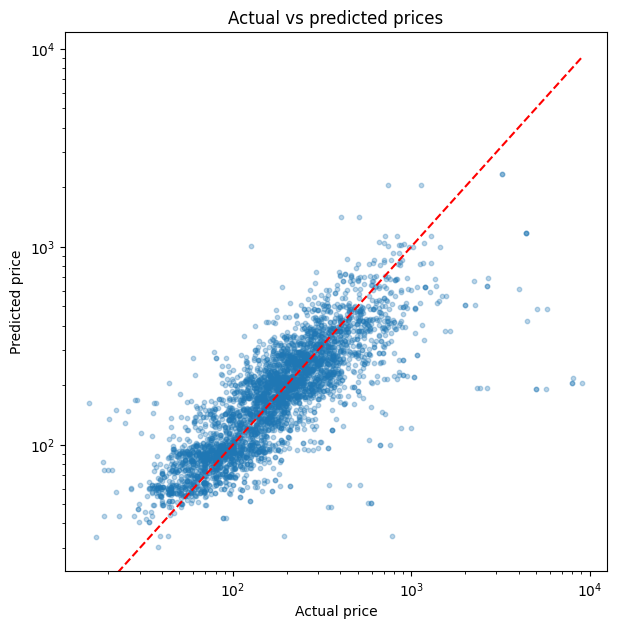

In [16]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.3,
    s=10
)

max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [0, max_value],
    [0, max_value],
    "--",
    color="red"
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs predicted prices")
plt.show()

room_type_Entire home/apt                        0.436775
bathrooms                                        0.163099
latitude                                         0.096427
longitude                                        0.091764
accommodates                                     0.064858
minimum_nights                                   0.029987
neighbourhood_cleansed_Westminster               0.024403
bedrooms                                         0.020757
neighbourhood_cleansed_Kensington and Chelsea    0.013981
beds                                             0.009399
property_type_Room in hotel                      0.009271
neighbourhood_cleansed_Camden                    0.004179
neighbourhood_cleansed_Lambeth                   0.003299
property_type_Entire rental unit                 0.002917
property_type_Private room in home               0.002225
dtype: float64

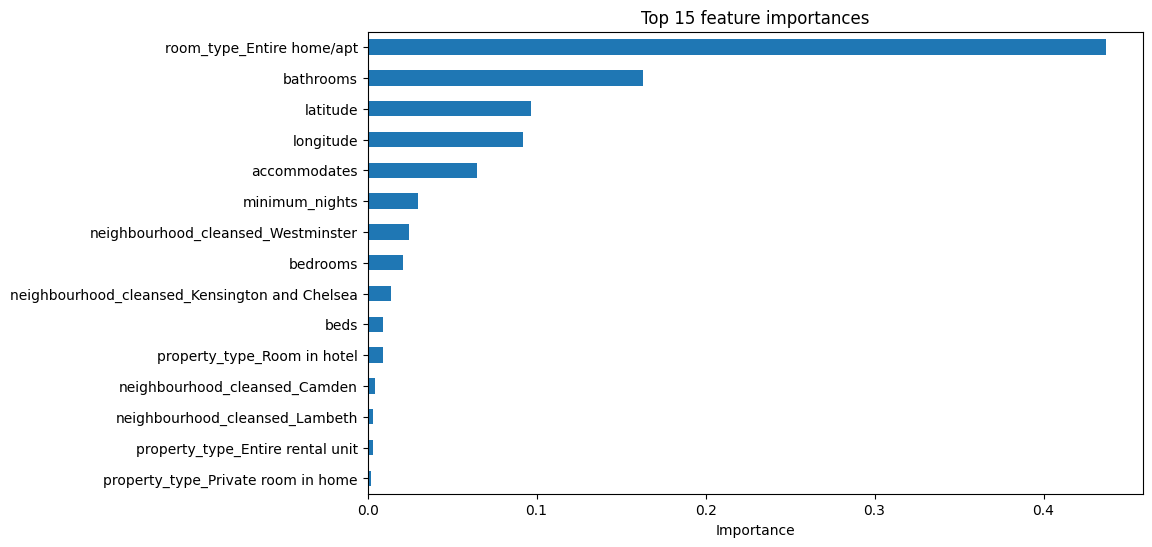

In [17]:
feature_names = (
    NUM_FEATURES
    + encoder.get_feature_names_out(
        CAT_FEATURES
    ).tolist()
)

importance = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

display(importance.head(15))

importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 15 feature importances")
plt.xlabel("Importance")
plt.show()

## Выводы

В ходе работы проведён первичный анализ данных Inside Airbnb, выполнена предобработка и обучена модель Random Forest для прогнозирования стоимости аренды жилья.

Исходный датасет содержит 20 151 наблюдение и 13 колонок. После удаления 960 дубликатов осталось 19 191 наблюдение. В связи с выраженной правосторонней асимметрией распределения целевой переменной использовано логарифмическое преобразование цены.

Разделение данных на обучающую и тестовую выборки выполнено с помощью GroupShuffleSplit по listing_id в пропорции 80/20. Пересечение идентификаторов объявлений между выборками отсутствует.

Random Forest показал улучшение качества относительно Baseline:

- MAE снизилась с 149,546 до 94,824 (на 36,6%).
- RMSE снизилась с 426,094 до 379,137 (на 11,0%).
- R² увеличился с −0,030 до 0,185.

Наиболее значимыми признаками для модели оказались тип арендуемого жилья, количество ванных комнат, географические координаты и вместимость.

Основным ограничением модели является недостаточная точность прогнозирования стоимости дорогих объектов. В дальнейшем качество модели можно улучшить за счёт подбора гиперпараметров, генерации дополнительных признаков и использования алгоритмов градиентного бустинга.